# 02 · Barren plateaus: when quantum models stop learning

**QGAI open notebooks · Track: Quantum Generative AI (trainability)**

Variational quantum models are trained with gradients. For many random circuits the gradients become **exponentially small** as
the number of qubits grows, a *barren plateau*. Training then needs exponentially many measurements just to see which way to move.

We measure the variance of one gradient component over many random initialisations, for $n = 2 \dots 10$ qubits, in three settings:

| Setting | Cost function | Depth |
|---|---|---|
| A | **Global**: overlap with $|0\dots0\rangle$ | shallow (2 layers) |
| B | **Local**: average single-qubit $\langle Z_i \rangle$ | shallow (2 layers) |
| C | **Local** | deep (3n layers) |

Theory (McClean et al. 2018; Cerezo et al. 2021) predicts A and C decay exponentially, while B decays much more slowly.
Here we check that prediction on a simulator. Gradients use the exact parameter-shift rule, and seeds are fixed.

In [1]:
import time
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

SEED = 1
rng = np.random.default_rng(SEED)
SAMPLES = 200
QUBITS = list(range(2, 11))

## The random circuit
Start with $R_Y(\pi/4)$ on every qubit, then repeat: a random choice of $R_X$, $R_Y$ or $R_Z$ with a random angle on each qubit, followed by a ladder of CZ gates.
We take the derivative with respect to the **first** rotation angle.

In [2]:
GATES = [qml.RX, qml.RY, qml.RZ]

def make_cost(n, layers, kind):
    dev = qml.device("default.qubit", wires=n)

    @qml.qnode(dev)
    def circuit(theta, gate_ids):
        for w in range(n):
            qml.RY(np.pi / 4, wires=w)
        k = 0
        for _ in range(layers):
            for w in range(n):
                GATES[gate_ids[k]](theta[k], wires=w); k += 1
            for w in range(n - 1):
                qml.CZ(wires=[w, w + 1])
        if kind == "global":
            return qml.expval(qml.Projector([0] * n, wires=range(n)))
        return qml.expval(qml.sum(*[qml.PauliZ(w) for w in range(n)]) / n)
    return circuit

def grad_variance(n, layers, kind):
    cost = make_cost(n, layers, kind)
    grads = []
    for _ in range(SAMPLES):
        m = n * layers
        theta = rng.uniform(0, 2 * np.pi, m)
        ids = rng.integers(0, 3, m)
        shift = np.zeros(m); shift[0] = np.pi / 2
        g = (cost(theta + shift, ids) - cost(theta - shift, ids)) / 2   # exact parameter-shift gradient
        grads.append(float(g))
    return float(np.var(grads))

In [3]:
settings = {
    "A: global cost, 2 layers": lambda n: (2, "global"),
    "B: local cost, 2 layers": lambda n: (2, "local"),
    "C: local cost, 3n layers": lambda n: (3 * n, "local"),
}
variances = {name: [] for name in settings}
t = time.time()
for name, cfg in settings.items():
    for n in QUBITS:
        layers, kind = cfg(n)
        variances[name].append(grad_variance(n, layers, kind))
print(f"computed {len(settings) * len(QUBITS) * SAMPLES * 2:,} circuit evaluations in {time.time() - t:.0f}s")

print(f"\n{'qubits':>6} " + " ".join(f"{k[:25]:>26s}" for k in settings))
for i, n in enumerate(QUBITS):
    print(f"{n:>6} " + " ".join(f"{variances[k][i]:>26.2e}" for k in settings))

computed 10,800 circuit evaluations in 66s

qubits   A: global cost, 2 layers    B: local cost, 2 layers   C: local cost, 3n layers
     2                   2.33e-02                   4.62e-02                   4.60e-02
     3                   9.20e-03                   2.18e-02                   1.25e-02
     4                   3.45e-03                   1.68e-02                   6.47e-03
     5                   1.95e-03                   7.64e-03                   2.44e-03
     6                   7.58e-04                   5.40e-03                   2.03e-03
     7                   1.99e-04                   3.89e-03                   1.04e-03
     8                   1.06e-04                   3.22e-03                   6.87e-04
     9                   2.85e-05                   2.19e-03                   3.91e-04
    10                   2.94e-05                   1.99e-03                   2.35e-04


## Exponential fit
If $\mathrm{Var}[\partial C] \propto b^{-n}$, then $\log_{10}\mathrm{Var}$ is a straight line in $n$. We fit the slope and report the decay factor per added qubit.

setting                        decay factor per qubit
A: global cost, 2 layers                        2.43x
B: local cost, 2 layers                         1.48x
C: local cost, 3n layers                        1.85x


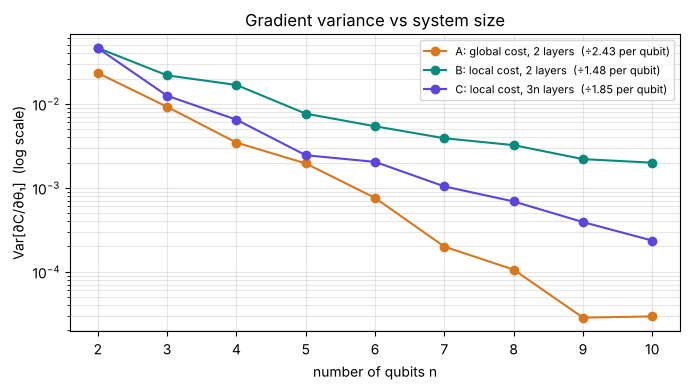

In [4]:
colors = {"A": "#d9771f", "B": "#0a8a7c", "C": "#5a45dd"}
plt.figure(figsize=(7, 4))
print(f"{'setting':28s} {'decay factor per qubit':>24s}")
for name in settings:
    v = np.array(variances[name])
    slope, intercept = np.polyfit(QUBITS, np.log10(v), 1)
    print(f"{name:28s} {10 ** (-slope):>23.2f}x")
    plt.semilogy(QUBITS, v, "o-", color=colors[name[0]], label=f"{name}  (÷{10 ** (-slope):.2f} per qubit)")
plt.xlabel("number of qubits n"); plt.ylabel("Var[∂C/∂θ₁]  (log scale)")
plt.title("Gradient variance vs system size"); plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

## What this means for quantum generative models

In this run (fixed seed, 200 samples per point):

- **A · global cost, shallow:** variance falls about **2.4× per added qubit**. Even a 2-layer circuit has a barren plateau when the cost compares *all* qubits at once.
- **C · local cost, deep:** about **1.9× per qubit**. Depth alone is enough to flatten the landscape.
- **B · local cost, shallow:** only about **1.5× per qubit** over this range. Part of that is the expected, merely polynomial $1/n^2$ effect of averaging the cost over $n$ qubits, so over 2–10 qubits the fit overstates the decay. B is the trainable regime.

At 2.4× per qubit, a 50-qubit model would see gradients about $10^{-19}$ times smaller than at 1 qubit, impossible to estimate with any realistic number of measurements.

**Design consequences:** local cost functions and shallow, problem-inspired circuits keep gradients measurable. QGAI's generative models (notebooks 01 and 03) use shallow circuits for this reason.

**Caveat:** recent work argues that circuits which provably avoid barren plateaus are often efficiently *simulable* classically. Trainability and quantum advantage pull in opposite directions; that tension is a central open question in quantum machine learning.

**Try next:** increase `SAMPLES` for tighter estimates; go beyond 10 qubits; try a correlated (non-random) initialisation and see whether it escapes the plateau.